# Forecasting Monthly Sales for a New Beverage Product
**AI in Operations – Session II Lab Activity** · MAIB, SP Jain School of Global Management

**Scenario.** A beverage company has launched a new flavored water product in regional markets.
It has collected monthly sales for the first year and wants to forecast the coming months to
optimise production and distribution.

**What this notebook does (the seven lab tasks):**

| # | Task | Section |
|---|------|---------|
| 1 | Preprocess: lag features and seasonal indicators | §4 |
| 2 | Choose forecasting models: Naive, ARIMA, Random Forest | §5 |
| 3 | Train and test with a chronological train-test split | §7 |
| 4 | Forecast the next 3 months | §8 |
| 5 | Evaluate with MAPE and WAPE | §6, §9 |
| 6 | Plot actual vs predicted sales | §10 |
| 7 | Interpret: seasonality and trends, best model and why, recommendations | §11 |
| + | **LLM interpretation based on real-time data** | §12 |

**Data.** Kaggle *Beverage Sales* (SWillm, 2025, MIT licence): about 9 million synthetic order
lines from German wholesalers, 2021-2023. We use **Volvic Touch**, the dataset's only *flavored*
water, as a stand-in for the new product, and treat **2021 as its first year**.

## 1. Setup
Imports, file paths and a consistent colour palette. The palette (one fixed colour per model)
was checked for colour-blind safety, and every chart also carries a legend or direct labels.
The forecasting engine below is the same Python file the dashboard runs in the browser.

In [1]:
# --- engine block 'imports' (identical to dashboard/public/py/forecast_core.py) ---
import calendar
import hashlib
import json
import re
import warnings

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.arima.model import ARIMA

SEED = 42          # fixed seed -> reproducible Random Forest
N_LAGS = 3         # lag features: sales 1, 2 and 3 months back
MIN_TRAIN = 6      # smallest training window: 3 lags + at least 3 usable rows
MAX_TEST = 6
MAX_HORIZON = 6
Z95 = 1.959964     # z-value for a 95% interval
MAPE_EPS = 1.0     # actuals with |A| <= 1 unit are treated as zero and skipped by MAPE

MODEL_KEYS = ["naive", "arima", "random_forest"]
MODEL_LABELS = {"naive": "Naive", "arima": "ARIMA", "random_forest": "Random Forest"}

Calendar helpers used throughout (days in a month, next month).

In [2]:
# --- engine block 'calendar' (identical to dashboard/public/py/forecast_core.py) ---
def days_in_month(month: str) -> int:
    """Number of calendar days in a 'YYYY-MM' month (28-31)."""
    year, mon = map(int, month.split("-"))
    return calendar.monthrange(year, mon)[1]


def next_month(month: str) -> str:
    """'2021-12' -> '2022-01'."""
    year, mon = map(int, month.split("-"))
    year, mon = (year + 1, 1) if mon == 12 else (year, mon + 1)
    return f"{year:04d}-{mon:02d}"


def future_months(last: str, horizon: int) -> list:
    """The `horizon` months that follow `last`."""
    out, cur = [], last
    for _ in range(horizon):
        cur = next_month(cur)
        out.append(cur)
    return out

In [3]:
import os
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RAW_CSV = ROOT / "data" / "synthetic_beverage_sales_data.csv"
EXPORT_DIR = ROOT / "dashboard" / "public" / "data"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

PRODUCT = "Volvic Touch"     # the flavored water used as the new product
FIRST_YEAR = 12              # months in the product's first year (Jan-Dec 2021)

# Fixed colour per series (validated categorical palette)
INK = "#1f2328"
COLORS = {"actual": INK, "naive": "#2a78d6", "arima": "#eb6834", "random_forest": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
                     "axes.edgecolor": "#8a8986", "font.size": 10, "axes.titleweight": "bold",
                     "lines.linewidth": 2})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter


def fmt_units(*axes):
    # thousands separators on unit axes, e.g. 160,000
    for ax in axes:
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))


print("Raw data found:", RAW_CSV.exists())

Raw data found: True


## 2. Load the raw data and check its quality
The raw file is about 790 MB, so it is read in chunks of 1 million rows. For every row we check:
missing values, invalid dates, non-positive quantities, and whether
`Total_Price = Unit_Price × Quantity × (1 − Discount)`. For the product itself we keep monthly
units, the number of days with orders, and the region and channel (B2B/B2C) split.

In [4]:
checks = {"rows": 0, "missing_values": 0, "bad_dates": 0, "non_positive_qty": 0,
          "price_mismatch": 0}
dates_min, dates_max, categories, parts = None, None, {}, []

for chunk in pd.read_csv(RAW_CSV, chunksize=1_000_000):
    checks["rows"] += len(chunk)
    checks["missing_values"] += int(chunk.isna().sum().sum())
    d = pd.to_datetime(chunk["Order_Date"], errors="coerce")
    checks["bad_dates"] += int(d.isna().sum())
    checks["non_positive_qty"] += int((chunk["Quantity"] <= 0).sum())
    expected = (chunk["Unit_Price"] * chunk["Quantity"] * (1 - chunk["Discount"])).round(2)
    checks["price_mismatch"] += int(((expected - chunk["Total_Price"]).abs() > 0.05).sum())
    dates_min = d.min() if dates_min is None else min(dates_min, d.min())
    dates_max = d.max() if dates_max is None else max(dates_max, d.max())
    for k, v in chunk["Category"].value_counts().items():
        categories[k] = categories.get(k, 0) + int(v)
    p = chunk[chunk["Product"] == PRODUCT].assign(Order_Date=d)
    parts.append(p[["Order_Date", "Quantity", "Region", "Customer_Type"]])

orders = pd.concat(parts, ignore_index=True)
print(pd.Series(checks).to_string())
print("Date range:", dates_min.date(), "to", dates_max.date())
print("Category rows:", categories)
print(f"{PRODUCT}: {len(orders):,} order lines")

rows                8999910
missing_values            0
bad_dates                 0
non_positive_qty          0
price_mismatch            0
Date range: 2021-01-01 to 2023-12-30
Category rows: {'Soft Drinks': 2248131, 'Alcoholic Beverages': 2251625, 'Juices': 2249937, 'Water': 2250217}
Volvic Touch: 248,967 order lines


**Reading.** The data is clean: no missing values, no invalid dates, no zero or negative
quantities, and every `Total_Price` is consistent. The four categories are balanced (about 25%
each). One gap matters: **2023-12-31 has no orders**, so December 2023 covers 30 days. We record
the days observed per month so this partial month is not mistaken for a demand drop.

## 3. Aggregate to monthly sales and export for the dashboard
Monthly units are the forecasting target. We also keep `days` (days with orders in the month)
and a region and channel breakdown, which supports the distribution recommendations. These small
files are the only precomputed data the dashboard uses: the 790 MB raw file cannot be shipped
to a browser or committed to GitHub.

In [5]:
orders["Month"] = orders["Order_Date"].dt.to_period("M").astype(str)
monthly = (orders.groupby("Month")
           .agg(units=("Quantity", "sum"), days=("Order_Date", lambda s: s.dt.date.nunique()))
           .reset_index().rename(columns={"Month": "month"}))
monthly["units"] = monthly["units"].astype(float)

breakdown = {}
for m, g in orders.groupby("Month"):
    breakdown[m] = {"regions": g.groupby("Region")["Quantity"].sum().astype(int).to_dict(),
                    "channels": g.groupby("Customer_Type")["Quantity"].sum().astype(int).to_dict()}

all_records = monthly.to_dict("records")
_ = (EXPORT_DIR / "volvic_touch_monthly.json").write_text(json.dumps(all_records), encoding="utf-8")
_ = (EXPORT_DIR / "breakdown.json").write_text(json.dumps(breakdown, ensure_ascii=False), encoding="utf-8")
print(f"{len(monthly)} months exported; partial months:",
      monthly.loc[monthly["days"] < monthly["month"].map(days_in_month), "month"].tolist())
monthly.head(12)

36 months exported; partial months: ['2023-12']


,month,units,days
0,2021-01,"159,013.00",31
1,2021-02,"145,774.00",28
2,2021-03,"164,952.00",31
3,2021-04,"152,966.00",30
4,2021-05,"159,563.00",31
5,2021-06,"157,079.00",30
6,2021-07,"166,034.00",31
7,2021-08,"160,660.00",31
8,2021-09,"158,666.00",30
9,2021-10,"167,105.00",31


### The product's first year
The lab scenario has **one year** of history: January to December 2021 (12 points). The
remaining 2022-2023 months are kept aside. The dashboard releases them one at a time as
"newly arriving" actuals (the real-time feed).

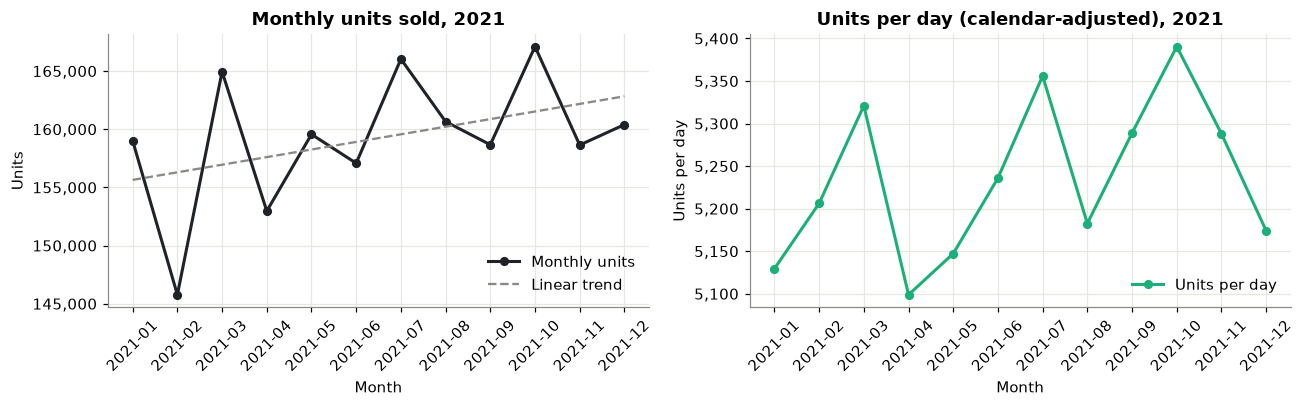

Trend: 0.19% per month | CV raw 3.49% -> per day 1.71% | month length explains 75.9% of the variation


In [6]:
first_year = [{**r, "source": "history"} for r in all_records[:FIRST_YEAR]]
fy = pd.DataFrame(first_year)
fy["per_day"] = fy["units"] / fy["days"]
t = np.arange(len(fy))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(fy["month"], fy["units"], color=INK, marker="o", ms=5, label="Monthly units")
axes[0].plot(fy["month"], np.poly1d(np.polyfit(t, fy["units"], 1))(t), color="#8a8986",
             ls="--", lw=1.5, label="Linear trend")
axes[0].set(title="Monthly units sold, 2021", xlabel="Month", ylabel="Units")
axes[1].plot(fy["month"], fy["per_day"], color=COLORS["random_forest"], marker="o", ms=5,
             label="Units per day")
axes[1].set(title="Units per day (calendar-adjusted), 2021", xlabel="Month", ylabel="Units per day")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.legend(frameon=False, loc="lower right")
fmt_units(*axes)
plt.tight_layout(); plt.show()

slope = np.polyfit(t, fy["per_day"], 1)[0]
cv = lambda s: 100 * s.std(ddof=0) / s.mean()
calendar_share = 100 * (1 - np.var(fy["per_day"] * fy["days"].mean()) / np.var(fy["units"]))
print(f"Trend: {100 * slope / fy['per_day'].mean():.2f}% per month | CV raw {cv(fy['units']):.2f}% "
      f"-> per day {cv(fy['per_day']):.2f}% | month length explains {calendar_share:.1f}% of the variation")

**Reading.** Raw monthly sales move between about 146k and 167k units. The sharpest dip is
**February**, which has only 28 days. Dividing by the days in each month removes most of that
movement: month length alone explains about three-quarters of the month-to-month variation, and
the coefficient of variation halves. The trend is essentially flat (about +0.2% per month).
With only one year of data, a true seasonal pattern (for example a summer peak) **cannot be
identified**: every calendar month has been seen once.

## 4. Task 1: Preprocessing, lag features and seasonal indicators
**Validation.** Months must be consecutive: a missing month would silently
shift every lag feature.

In [7]:
# --- engine block 'prepare' (identical to dashboard/public/py/forecast_core.py) ---
def prepare_series(records) -> pd.DataFrame:
    """Validate and tidy a monthly series.

    records: list of dicts with 'month' ('YYYY-MM'), 'units', and optionally
    'days' (days actually observed in that month) and 'source'.
    Months must be consecutive - a gap would silently break lag features.
    """
    df = pd.DataFrame(list(records))
    if df.empty or "month" not in df or "units" not in df:
        raise ValueError("Series needs 'month' and 'units' columns.")
    df["month"] = df["month"].astype(str).str.slice(0, 7)
    df = df.sort_values("month").drop_duplicates("month", keep="last").reset_index(drop=True)
    for prev, cur in zip(df["month"][:-1], df["month"][1:]):
        if next_month(prev) != cur:
            raise ValueError(f"Months must be consecutive: gap between {prev} and {cur}.")
    df["units"] = pd.to_numeric(df["units"], errors="raise").astype(float)
    if (df["units"] < 0).any():
        raise ValueError("Units cannot be negative.")
    if "days" not in df:
        df["days"] = np.nan
    df["days"] = df["days"].fillna(df["month"].map(days_in_month)).astype(float)
    if "source" not in df:
        df["source"] = "history"
    df["source"] = df["source"].fillna("history")
    return df[["month", "units", "days", "source"]]

**Feature engineering.**
* **Calendar adjustment**: model *units per day*, then multiply back by the days in the month.
  This is the most useful feature for this data, because it turns the February "dip" into what
  it is: fewer days.
* **Lag features**: `lag_1`, `lag_2` and `lag_3` (sales 1-3 months back) and `roll_mean_3`. They
  are built with `shift`, so a row only sees the past and nothing leaks from the future.
* **Seasonal indicators**: month-of-year as `sin` and `cos` (so December sits next to January),
  `quarter`, `days_in_month`, and a time index `t` for trend.

**Limits with 12 months.** A 12-month seasonal lag would need a full year *before* the first
training row, so it is impossible here. Three lags already use up 3 of the 12 rows.

In [8]:
# --- engine block 'features' (identical to dashboard/public/py/forecast_core.py) ---
FEATURE_COLS = ["lag_1", "lag_2", "lag_3", "roll_mean_3", "t",
                "month_sin", "month_cos", "days_in_month"]


def build_features(df: pd.DataFrame, adjust: bool = True) -> pd.DataFrame:
    """Task 1 - lag features and seasonal indicators.

    adjust=True models units per day (calendar adjustment): a 28-day February
    then no longer looks like a demand drop. Lags only look backwards (shift),
    so no future information leaks into a row.
    """
    out = df[["month", "units", "days"]].copy()
    out["target"] = out["units"] / out["days"] if adjust else out["units"]
    for k in range(1, N_LAGS + 1):
        out[f"lag_{k}"] = out["target"].shift(k)
    out["roll_mean_3"] = out["target"].shift(1).rolling(3).mean()
    out["t"] = np.arange(len(out))                      # time index -> trend
    month_num = out["month"].str.slice(5, 7).astype(int)
    out["month_num"] = month_num
    out["month_sin"] = np.sin(2 * np.pi * month_num / 12)  # cyclical month encoding
    out["month_cos"] = np.cos(2 * np.pi * month_num / 12)
    out["quarter"] = (month_num - 1) // 3 + 1
    out["days_in_month"] = out["month"].map(days_in_month)
    return out


def _feature_row(history, t, month):
    """Feature vector for one month, built only from values before it."""
    m = int(month[5:7])
    return [history[-1], history[-2], history[-3], float(np.mean(history[-3:])), t,
            np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12), days_in_month(month)]

In [9]:
features = build_features(prepare_series(first_year), adjust=True)
display(features[["month", "units", "days", "target", "lag_1", "lag_2", "lag_3", "roll_mean_3",
                  "t", "month_sin", "month_cos", "quarter", "days_in_month"]].round(3))

,month,units,days,target,lag_1,lag_2,lag_3,roll_mean_3,t,month_sin,month_cos,quarter,days_in_month
0,2021-01,"159,013.00",31.00,"5,129.45",NaN,NaN,NaN,NaN,0,0.50,0.87,1,31
1,2021-02,"145,774.00",28.00,"5,206.21","5,129.45",NaN,NaN,NaN,1,0.87,0.50,1,28
2,2021-03,"164,952.00",31.00,"5,321.03","5,206.21","5,129.45",NaN,NaN,2,1.00,0.00,1,31
3,2021-04,"152,966.00",30.00,"5,098.87","5,321.03","5,206.21","5,129.45","5,218.90",3,0.87,-0.50,2,30
4,2021-05,"159,563.00",31.00,"5,147.19","5,098.87","5,321.03","5,206.21","5,208.70",4,0.50,-0.87,2,31
5,2021-06,"157,079.00",30.00,"5,235.97","5,147.19","5,098.87","5,321.03","5,189.03",5,0.00,-1.00,2,30
6,2021-07,"166,034.00",31.00,"5,355.94","5,235.97","5,147.19","5,098.87","5,160.68",6,-0.50,-0.87,3,31
7,2021-08,"160,660.00",31.00,"5,182.58","5,355.94","5,235.97","5,147.19","5,246.36",7,-0.87,-0.50,3,31
8,2021-09,"158,666.00",30.00,"5,288.87","5,182.58","5,355.94","5,235.97","5,258.16",8,-1.00,-0.00,3,30
9,2021-10,"167,105.00",31.00,"5,390.48","5,288.87","5,182.58","5,355.94","5,275.79",9,-0.87,0.50,4,31


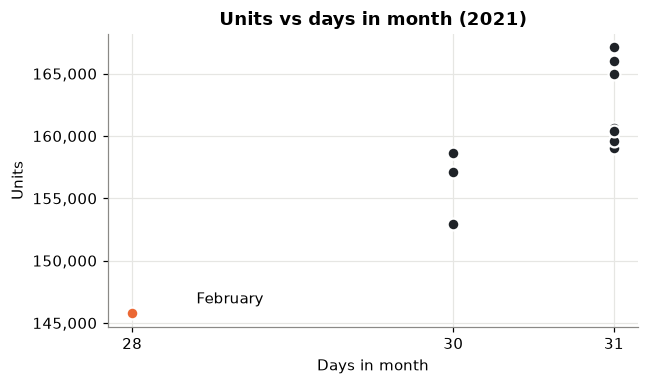

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for d, g in fy.assign(dim=fy["month"].map(days_in_month)).groupby("dim"):
    ax.scatter(g["dim"], g["units"], s=60, color=INK if d != 28 else COLORS["arima"],
               edgecolor="white", linewidth=1.5, zorder=3)
ax.set(title="Units vs days in month (2021)", xlabel="Days in month", ylabel="Units",
       xticks=[28, 30, 31])
ax.annotate("February", (28, fy["units"].min()), xytext=(28.4, fy["units"].min() + 800))
fmt_units(ax)
plt.tight_layout(); plt.show()

**Reading.** The first three rows have empty lags, so the Random Forest can learn only from the
rows that have all three lags. The scatter shows the calendar effect directly: the 28-day month
is clearly lowest, and 31-day months sit highest on average.

## 5. Task 2: Choosing the forecasting models
We compare three models from the lab brief, from simplest to most flexible:

| Model | Why it is included | Fit for 12 months of data |
|---|---|---|
| **Naive** | Benchmark: next month = last month. Any useful model must beat it. | Always works |
| **ARIMA** | Classic statistical model for autocorrelation and trend. Orders (p,d,q) in {0,1} are chosen by **AICc** (AIC corrected for small samples). | Only small, non-seasonal orders can be estimated from about 9 points; seasonal ARIMA needs at least 2 years |
| **Random Forest** | ML model using the lag and seasonal-indicator features. Forecasts *recursively* (each prediction becomes the next lag). | Learns from very few rows; cannot extrapolate a trend |

XGBoost (also listed on the slide) is left out on purpose: a boosted model on about 6 training
rows adds complexity without information. Each model returns a point forecast and a 95% range.

In [11]:
# --- engine block 'models' (identical to dashboard/public/py/forecast_core.py) ---
class NaiveModel:
    """Next month = last observed month. The benchmark every model must beat."""

    def fit(self, target, months):
        self.y = np.asarray(target, float)
        diffs = np.diff(self.y)
        # spread of month-to-month changes drives the random-walk interval
        self.sigma = float(np.std(diffs, ddof=1)) if len(diffs) >= 2 else float("nan")
        return self

    def forecast(self, months):
        h = len(months)
        mean = np.repeat(self.y[-1], h)
        spread = Z95 * self.sigma * np.sqrt(np.arange(1, h + 1))
        return mean, mean - spread, mean + spread

    def describe(self):
        return {"rule": "forecast = last observed value",
                "interval": "95% random-walk band (1.96 x sd of monthly changes x sqrt(h))"}


ARIMA_GRID = [(p, d, q) for d in (0, 1) for p in (0, 1) for q in (0, 1)]


class ArimaModel:
    """ARIMA(p,d,q) with p,d,q in {0,1}, chosen by AICc.

    A small grid on purpose: with 6-12 points, larger or seasonal models
    cannot be estimated reliably.
    """

    def fit(self, target, months):
        y = np.asarray(target, float)
        best = None
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")  # tiny samples trigger convergence warnings
            for order in ARIMA_GRID:
                trend = "c" if order[1] == 0 else "n"
                try:
                    res = ARIMA(y, order=order, trend=trend).fit()
                except Exception:
                    continue
                if np.isfinite(res.aicc) and (best is None or res.aicc < best[0]):
                    best = (float(res.aicc), order, res)
        if best is None:
            raise RuntimeError("No ARIMA order could be fitted.")
        self.aicc, self.order, self.res = best
        return self

    def forecast(self, months):
        fc = self.res.get_forecast(len(months))
        ci = np.asarray(fc.conf_int(alpha=0.05))
        return np.asarray(fc.predicted_mean), ci[:, 0], ci[:, 1]

    def describe(self):
        return {"order": f"({self.order[0]},{self.order[1]},{self.order[2]})",
                "aicc": round(self.aicc, 2),
                "interval": "95% ARIMA prediction interval"}


class RandomForestModel:
    """Random Forest on lag + seasonal-indicator features, forecasting recursively
    (each prediction becomes the next month's lag_1)."""

    def fit(self, target, months):
        target = list(map(float, target))
        X = [_feature_row(target[:i], i, months[i]) for i in range(N_LAGS, len(target))]
        y = target[N_LAGS:]
        if len(y) < 3:
            raise RuntimeError("Random Forest needs at least 3 rows after creating lags.")
        self.rf = RandomForestRegressor(n_estimators=300, random_state=SEED)
        self.rf.fit(np.array(X), np.array(y))
        self.history, self.n, self.rows = target, len(target), len(y)
        return self

    def forecast(self, months):
        hist, means, lows, highs = list(self.history), [], [], []
        for k, month in enumerate(months):
            x = np.array([_feature_row(hist, self.n + k, month)])
            trees = np.array([tree.predict(x)[0] for tree in self.rf.estimators_])
            mean = float(trees.mean())
            means.append(mean)
            lows.append(float(np.percentile(trees, 2.5)))
            highs.append(float(np.percentile(trees, 97.5)))
            hist.append(mean)
        return np.array(means), np.array(lows), np.array(highs)

    def describe(self):
        return {"features": FEATURE_COLS, "training_rows": self.rows, "trees": 300,
                "interval": "2.5-97.5% spread of the 300 trees (not a calibrated interval)"}


MODEL_CLASSES = {"naive": NaiveModel, "arima": ArimaModel, "random_forest": RandomForestModel}

## 6. Task 5 (formulas): MAPE and WAPE
Defined before training so that every model is scored by exactly the same code.

$$\text{MAPE} = \frac{100}{n}\sum_{t=1}^{n}\frac{|A_t - F_t|}{|A_t|} \qquad
\text{WAPE} = 100\cdot\frac{\sum_t |A_t - F_t|}{\sum_t |A_t|} \qquad
\text{Bias} = 100\cdot\frac{\sum_t (F_t - A_t)}{\sum_t A_t}$$

* **Zero or near-zero actuals**: MAPE divides by $A_t$, so months with $|A_t| \le 1$ unit are
  skipped (and counted). WAPE is undefined only if *all* actuals are zero; then it returns `None`.
* **WAPE** weights errors by volume, which matches production planning (units, not %-per-month).
  **Bias** shows the direction: positive means over-forecasting (overstock risk).

In [12]:
# --- engine block 'metrics' (identical to dashboard/public/py/forecast_core.py) ---
def mape(actual, forecast, eps=MAPE_EPS):
    """MAPE = 100/n * sum(|A - F| / |A|), over months where |A| > eps.

    Zero or near-zero actuals would divide by ~0, so they are skipped and counted.
    Returns (value or None, number_of_months_skipped).
    """
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    keep = np.abs(a) > eps
    if not keep.any():
        return None, int((~keep).sum())
    return float(100 * np.mean(np.abs(a[keep] - f[keep]) / np.abs(a[keep]))), int((~keep).sum())


def wape(actual, forecast):
    """WAPE = 100 * sum|A - F| / sum|A|. Undefined (None) when all actuals are 0."""
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    denom = np.abs(a).sum()
    return None if denom == 0 else float(100 * np.abs(a - f).sum() / denom)


def bias_pct(actual, forecast):
    """Bias = 100 * sum(F - A) / sum(A). Positive = over-forecast (risk of overstock)."""
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    denom = a.sum()
    return None if denom == 0 else float(100 * (f - a).sum() / denom)


def score(actual, forecast):
    m, skipped = mape(actual, forecast)
    return {"mape": m, "wape": wape(actual, forecast), "bias_pct": bias_pct(actual, forecast),
            "mape_skipped": skipped, "n": len(actual)}

**Hand-calculation cross-check** on three made-up months, worked out by hand and compared with the code.

In [13]:
A = [100, 200, 300]; F = [110, 190, 330]
# by hand: |errors| = 10, 10, 30
#   MAPE = (10/100 + 10/200 + 30/300) / 3 * 100 = (0.10 + 0.05 + 0.10) / 3 * 100 = 8.333...%
#   WAPE = (10 + 10 + 30) / (100 + 200 + 300) * 100 = 50 / 600 * 100 = 8.333...%
#   Bias = (10 - 10 + 30) / 600 * 100 = 5.0%
s = score(A, F)
assert abs(s["mape"] - 25 / 3) < 1e-9 and abs(s["wape"] - 50 / 6) < 1e-9 and abs(s["bias_pct"] - 5) < 1e-9

# zero actual: MAPE skips it, WAPE still works
m, skipped = mape([0, 100], [5, 90]); assert skipped == 1 and abs(m - 10) < 1e-9
assert abs(wape([0, 100], [5, 90]) - 15) < 1e-9          # (5 + 10) / 100
assert wape([0, 0], [1, 1]) is None and mape([0, 0], [1, 1])[0] is None
print("All metric checks passed:", {k: round(v, 4) for k, v in s.items() if isinstance(v, float)})

All metric checks passed: {'mape': 8.3333, 'wape': 8.3333, 'bias_pct': 5.0}


## 7. Task 3: Chronological train-test split and training
The data is a time series, so the split is **chronological, never random**. A random split
would let a model train on October to predict September.

* **Train**: Jan-Sep 2021 (9 months). **Test**: Oct-Dec 2021 (3 months), the same length as the
  3-month forecast horizon, so the test mimics the real task.
* Every model gets the same split, horizon and calendar setting.
* For the *future* forecast (Task 4), each model is refitted on all 12 months.

The pipeline below runs Tasks 1-5 in one call. The dashboard calls the same function whenever
the user changes a setting or adds data.

In [14]:
# --- engine block 'analysis' (identical to dashboard/public/py/forecast_core.py) ---
def describe_series(df: pd.DataFrame) -> dict:
    """Trend and seasonality facts the interpretation is based on."""
    units = df["units"].to_numpy(float)
    per_day = units / df["days"].to_numpy(float)
    n = len(df)
    t = np.arange(n)
    slope_day = float(np.polyfit(t, per_day, 1)[0]) if n >= 2 else 0.0
    mean_days = float(df["days"].mean())
    var_raw = float(np.var(units))
    # share of month-to-month variation that is only "different month lengths"
    calendar_share = 0.0 if var_raw == 0 else float(
        np.clip(1 - np.var(per_day * mean_days) / var_raw, 0, 1))
    moy = df["month"].str.slice(5, 7)
    profile = []
    for m in sorted(moy.unique()):
        mask = (moy == m).to_numpy()
        profile.append({"month_of_year": int(m), "observations": int(mask.sum()),
                        "raw_index": float(units[mask].mean() / units.mean()),
                        "per_day_index": float(per_day[mask].mean() / per_day.mean())})
    return {
        "n_months": n, "first_month": df["month"].iloc[0], "last_month": df["month"].iloc[-1],
        "full_years_observed": n // 12,
        "mean_units": float(units.mean()), "min_units": float(units.min()),
        "max_units": float(units.max()),
        "min_month": df["month"].iloc[int(units.argmin())],
        "max_month": df["month"].iloc[int(units.argmax())],
        "trend_units_per_day_per_month": slope_day,
        "trend_pct_per_month": float(100 * slope_day / per_day.mean()),
        "cv_raw_pct": float(100 * units.std() / units.mean()),
        "cv_per_day_pct": float(100 * per_day.std() / per_day.mean()),
        "calendar_share_of_variation_pct": 100 * calendar_share,
        "month_profile": profile,
    }


def distribution_shares(breakdown, months) -> dict:
    """Region and channel shares over the given months (from the raw order data)."""
    if not breakdown:
        return {}
    regions, channels = {}, {}
    for m in months:
        b = breakdown.get(m)
        if not b:
            continue
        for k, v in b["regions"].items():
            regions[k] = regions.get(k, 0) + v
        for k, v in b["channels"].items():
            channels[k] = channels.get(k, 0) + v
    if not regions:
        return {}
    rt, ct = sum(regions.values()), sum(channels.values())
    reg = sorted(((k, 100 * v / rt) for k, v in regions.items()), key=lambda kv: -kv[1])
    return {"months_covered": sum(1 for m in months if m in breakdown),
            "region_share_pct": {k: v for k, v in reg},
            "channel_share_pct": {k: 100 * v / ct for k, v in channels.items()}}

In [15]:
# --- engine block 'pipeline' (identical to dashboard/public/py/forecast_core.py) ---
def _clean(obj):
    """Make results JSON-safe: numpy -> python, NaN/inf -> None."""
    if isinstance(obj, dict):
        return {str(k): _clean(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_clean(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        return None if not np.isfinite(obj) else float(obj)
    return obj


def data_version(records, settings) -> str:
    """Short hash of the data + settings: any change -> new version."""
    blob = json.dumps({"r": [[r["month"], float(r["units"])] for r in records], "s": settings},
                      sort_keys=True)
    return hashlib.sha256(blob.encode()).hexdigest()[:10]


def run_pipeline(records, test_size=3, horizon=3, adjust=True, breakdown=None) -> dict:
    """Tasks 1-5 end to end: features, chronological split, train, test, forecast, score.

    All models get the same split, horizon and calendar setting (a fair comparison).
    The test forecast is made from the training window only; the future forecast is
    made after refitting on all available months.
    """
    df = prepare_series(records)
    n = len(df)
    if n < MIN_TRAIN + 1:
        raise ValueError(f"Need at least {MIN_TRAIN + 1} months of data.")
    test_size = int(np.clip(test_size, 1, min(MAX_TEST, n - MIN_TRAIN)))
    horizon = int(np.clip(horizon, 1, MAX_HORIZON))
    feats = build_features(df, adjust)
    target, months = feats["target"].to_numpy(float), list(df["month"])
    days, actual = df["days"].to_numpy(float), df["units"].to_numpy(float)
    split = n - test_size                                   # chronological split point
    fut_months = future_months(months[-1], horizon)
    fut_days = np.array([days_in_month(m) for m in fut_months], float)

    def to_units(values, d):
        return np.asarray(values) * d if adjust else np.asarray(values)

    models = {}
    for key in MODEL_KEYS:
        entry = {"key": key, "label": MODEL_LABELS[key]}
        try:
            fitted = MODEL_CLASSES[key]().fit(target[:split], months[:split])
            mean, lo, hi = (to_units(v, days[split:]) for v in fitted.forecast(months[split:]))
            entry["test"] = [{"month": months[split + i], "actual": actual[split + i],
                              "pred": mean[i], "lo": max(lo[i], 0), "hi": hi[i]}
                             for i in range(test_size)]
            entry["metrics"] = score(actual[split:], mean)
            entry["details"] = fitted.describe()
            final = MODEL_CLASSES[key]().fit(target, months)
            fmean, flo, fhi = (to_units(v, fut_days) for v in final.forecast(fut_months))
            entry["forecast"] = [{"month": fut_months[i], "pred": fmean[i],
                                  "lo": max(flo[i], 0), "hi": fhi[i]} for i in range(horizon)]
            entry["forecast_total"] = float(np.sum(fmean))
            entry["details_full_fit"] = final.describe()
        except Exception as exc:  # one model failing must not break the others
            entry["error"] = str(exc)
        models[key] = entry

    scored = [m for m in models.values() if m.get("metrics", {}).get("wape") is not None]
    best = min(scored, key=lambda m: (m["metrics"]["wape"], m["metrics"]["mape"] or 0))["key"] \
        if scored else None
    settings = {"test_size": test_size, "horizon": horizon, "calendar_adjusted": bool(adjust)}
    recs = df.to_dict("records")
    return _clean({
        "settings": settings,
        "data_version": data_version(recs, settings),
        "split": {"train_months": split, "test_months": test_size,
                  "train_end": months[split - 1], "test_start": months[split]},
        "series": recs,
        "features": feats.to_dict("records"),
        "models": models,
        "best_model": best,
        "analysis": describe_series(df),
        "distribution": distribution_shares(breakdown, months),
        "sources": df["source"].value_counts().to_dict(),
    })

In [16]:
result = run_pipeline(first_year, test_size=3, horizon=3, adjust=True, breakdown=breakdown)
print("Split:", result["split"])
for m in result["models"].values():
    print(f"{m['label']:<14}", m["details"])

# Export the default view so the dashboard can show it instantly while its Python engine loads
_ = (EXPORT_DIR / "default_results.json").write_text(json.dumps(result), encoding="utf-8")

Split: {'train_months': 9, 'test_months': 3, 'train_end': '2021-09', 'test_start': '2021-10'}
Naive          {'rule': 'forecast = last observed value', 'interval': '95% random-walk band (1.96 x sd of monthly changes x sqrt(h))'}
ARIMA          {'order': '(0,1,0)', 'aicc': 103.2, 'interval': '95% ARIMA prediction interval'}
Random Forest  {'features': ['lag_1', 'lag_2', 'lag_3', 'roll_mean_3', 't', 'month_sin', 'month_cos', 'days_in_month'], 'training_rows': 6, 'trees': 300, 'interval': '2.5-97.5% spread of the 300 trees (not a calibrated interval)'}


**Reading.** AICc picks **ARIMA(0,1,0)**: a random walk, which is *mathematically the same
forecast as Naive*. ARIMA found no autocorrelation worth modelling in 9 calendar-adjusted points.
That is a finding, not a bug. The Random Forest learned from only 6 rows.

## 8. Task 4: Forecasts for the next 3 months (Jan-Mar 2022)
Each model is refitted on all of 2021. The ranges are 95% intervals: random-walk for Naive,
ARIMA's own prediction interval, and the spread of the 300 trees for Random Forest (labelled as
not calibrated).

model,ARIMA,Naive,Random Forest
month,,,
2022-01,"160,396.00","160,396.00","162,361.00"
2022-02,"144,874.00","144,874.00","145,846.00"
2022-03,"160,396.00","160,396.00","160,605.00"


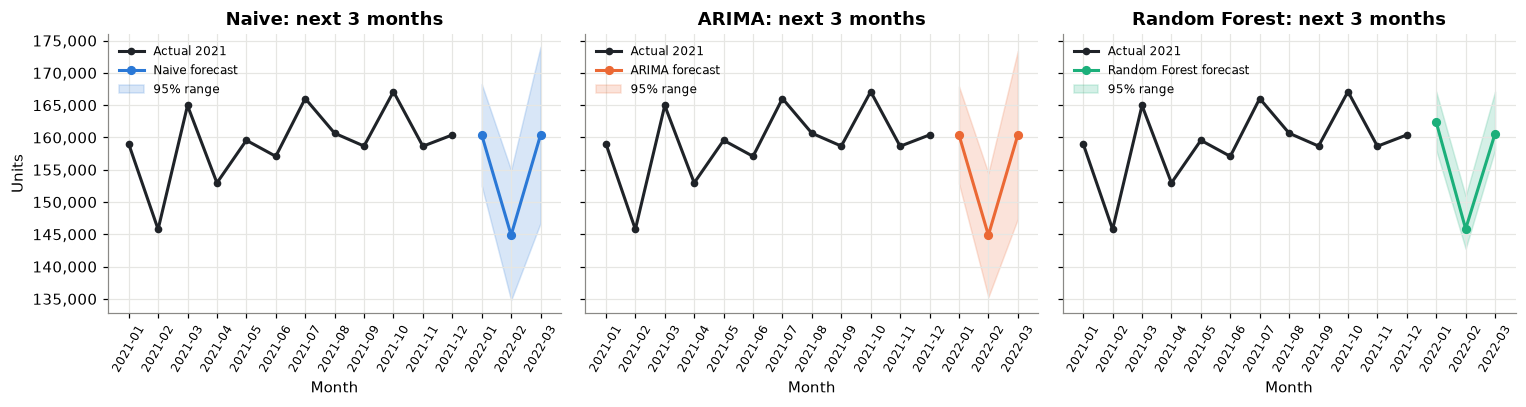

In [17]:
rows = []
for m in result["models"].values():
    for f in m["forecast"]:
        rows.append({"model": m["label"], "month": f["month"], "forecast": f["pred"],
                     "low_95": f["lo"], "high_95": f["hi"]})
fc_table = pd.DataFrame(rows)
display(fc_table.pivot(index="month", columns="model", values="forecast").round(0))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
hist = pd.DataFrame(result["series"])
for ax, (key, m) in zip(axes, result["models"].items()):
    f = pd.DataFrame(m["forecast"])
    ax.plot(hist["month"], hist["units"], color=INK, marker="o", ms=4, label="Actual 2021")
    ax.plot(f["month"], f["pred"], color=COLORS[key], marker="o", ms=5, label=f"{m['label']} forecast")
    ax.fill_between(f["month"], f["lo"], f["hi"], color=COLORS[key], alpha=0.18, label="95% range")
    ax.set(title=f"{m['label']}: next 3 months", xlabel="Month")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
axes[0].set_ylabel("Units"); fmt_units(*axes)
plt.tight_layout(); plt.show()

**Reading.** All three models forecast a dip in **February 2022**. That dip comes from the
calendar adjustment: per-day sales are held roughly flat and February has 28 days. Naive and
ARIMA agree exactly. Random Forest is slightly higher. The Naive and ARIMA ranges widen with
the horizon, as they should.

## 9. Task 5: Evaluating performance with MAPE and WAPE
All models are scored on the same three test months (Oct-Dec 2021). To show the value of the
calendar feature, we also run the identical comparison **without** calendar adjustment.

calendar-adjusted               raw units              
                         MAPE % WAPE % Bias %    MAPE % WAPE % Bias %
model                                                                
Naive                      1.37   1.38   0.09      2.05   2.10  -2.09
ARIMA                      1.37   1.38   0.09      2.94   2.99  -2.99
Random Forest              1.76   1.78  -0.76      1.58   1.61  -1.00

Best model (adjusted): Naive | best model (raw): Random Forest


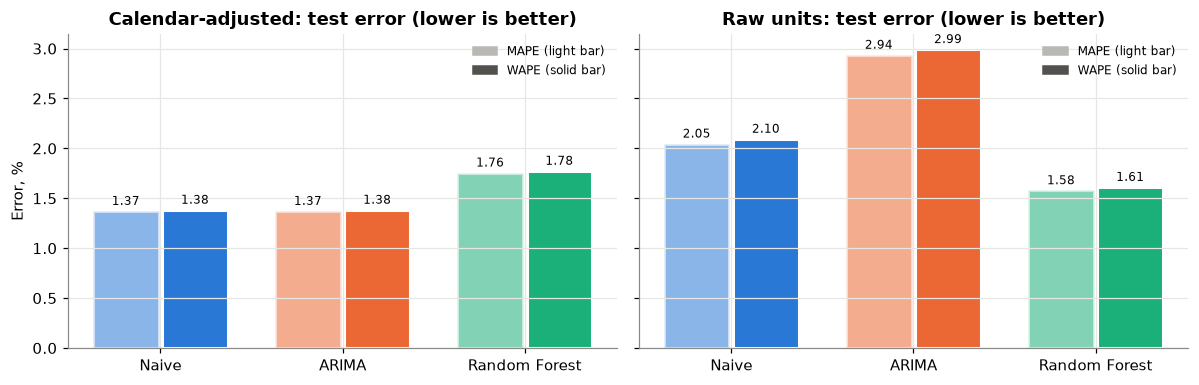

In [18]:
def metrics_table(res):
    return pd.DataFrame([{"model": m["label"], "MAPE %": m["metrics"]["mape"],
                          "WAPE %": m["metrics"]["wape"], "Bias %": m["metrics"]["bias_pct"]}
                         for m in res["models"].values()]).set_index("model")

result_raw = run_pipeline(first_year, test_size=3, horizon=3, adjust=False, breakdown=breakdown)
comparison = pd.concat({"calendar-adjusted": metrics_table(result),
                        "raw units": metrics_table(result_raw)}, axis=1)
display(comparison.round(2))
print("Best model (adjusted):", MODEL_LABELS[result["best_model"]],
      "| best model (raw):", MODEL_LABELS[result_raw["best_model"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, res) in zip(axes, [("Calendar-adjusted", result), ("Raw units", result_raw)]):
    tbl = metrics_table(res)
    x = np.arange(len(tbl))
    for i, metric in enumerate(["MAPE %", "WAPE %"]):
        bars = ax.bar(x + (i - 0.5) * 0.38, tbl[metric], width=0.36,
                      color=[COLORS[k] for k in res["models"]], alpha=1 if i else 0.55,
                      edgecolor="white", linewidth=2, label=metric)
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticks(x, tbl.index); ax.set(title=f"{name}: test error (lower is better)")
    ax.legend(handles=[Patch(color="#b9b8b4", label="MAPE (light bar)"),
                       Patch(color="#52514e", label="WAPE (solid bar)")], frameon=False, fontsize=8)
axes[0].set_ylabel("Error, %")
plt.tight_layout(); plt.show()

**Reading.**
* With calendar adjustment, **Naive and ARIMA tie for best (WAPE about 1.4%)**, ahead of Random
  Forest (about 1.8%).
* Without it, every simple model gets worse (Naive about 2.1%, ARIMA about 3.0%). Random Forest
  becomes the best raw model (about 1.6%), because its `days_in_month` feature partly learns the
  same calendar effect.
* **The feature engineering mattered more than the choice of algorithm.**
* MAPE and WAPE are nearly identical because monthly volumes are similar. They would diverge if
  some months were much smaller than others.
* All errors are under 3%: the series is stable. With only 3 test months, differences of a few
  tenths of a percent are **not statistically meaningful**.

## 10. Task 6: Actual vs predicted sales
Test-period predictions (made from the training window only) next to the actual sales, one
panel per model, followed by all models together.

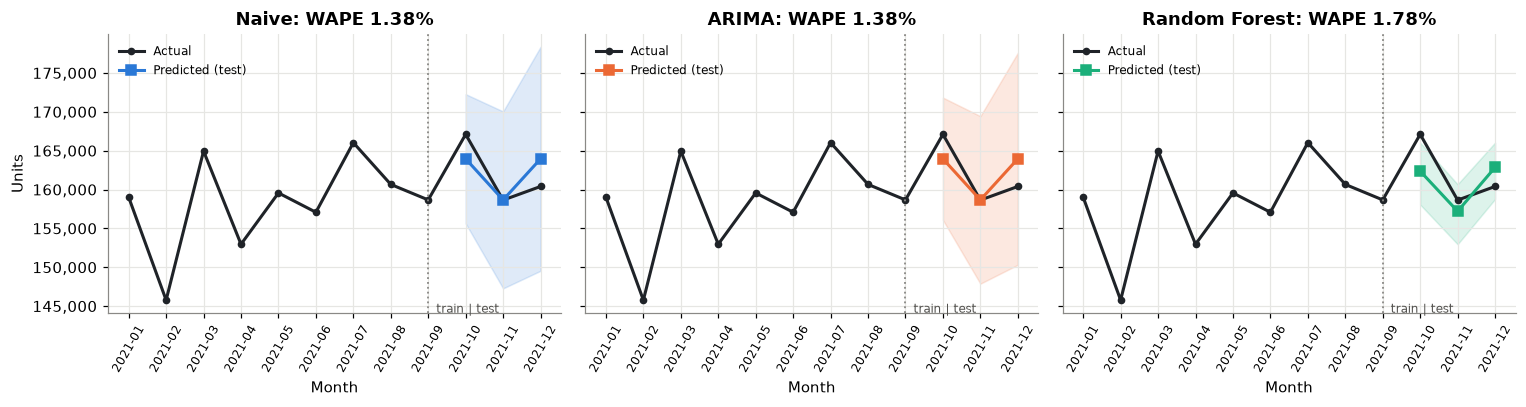

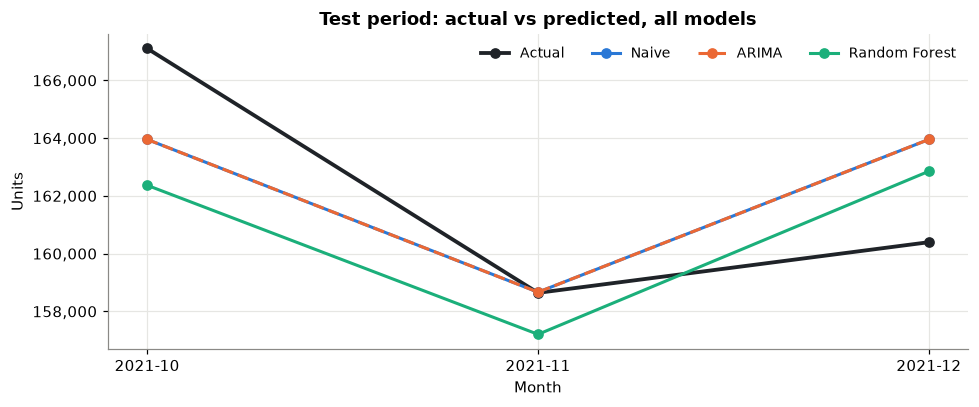

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (key, m) in zip(axes, result["models"].items()):
    tst = pd.DataFrame(m["test"])
    ax.plot(hist["month"], hist["units"], color=INK, marker="o", ms=4, label="Actual")
    ax.plot(tst["month"], tst["pred"], color=COLORS[key], marker="s", ms=6, label="Predicted (test)")
    ax.fill_between(tst["month"], tst["lo"], tst["hi"], color=COLORS[key], alpha=0.15)
    ax.axvline(result["split"]["train_end"], color="#8a8986", ls=":", lw=1.2)
    ax.text(result["split"]["train_end"], ax.get_ylim()[0], "  train | test", fontsize=8, color="#52514e")
    ax.set(title=f"{m['label']}: WAPE {m['metrics']['wape']:.2f}%", xlabel="Month")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
axes[0].set_ylabel("Units"); fmt_units(*axes)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.8))
tst_months = [t["month"] for t in result["models"]["naive"]["test"]]
ax.plot(tst_months, [t["actual"] for t in result["models"]["naive"]["test"]], color=INK,
        marker="o", lw=2.5, label="Actual")
for key, m in result["models"].items():
    ax.plot(tst_months, [t["pred"] for t in m["test"]], color=COLORS[key], marker="o",
            ls="--" if key == "arima" else "-", label=m["label"])
ax.set(title="Test period: actual vs predicted, all models", xlabel="Month", ylabel="Units")
ax.legend(frameon=False, ncol=4, fontsize=9); fmt_units(ax)
plt.tight_layout(); plt.show()

**Reading.** November 2021 is forecast almost exactly. The misses are October (actual about 167k,
above the forecast) and December (below it), each about 2%. These are ordinary month-to-month
swings that no model can learn from 9 points. ARIMA is drawn dashed because it sits exactly on
top of Naive.

## 11. Task 7: Interpreting the insights

**How well did the models capture seasonality or trends?**
There is almost no trend to capture (about +0.2% per month). The visible "seasonality" in 2021 is
mostly a **calendar effect**: month length explains about three-quarters of the month-to-month
variation. Once modelled per day, all models capture it, and every forecast correctly expects
a lower February. A real seasonal pattern (such as weather-driven summer demand) cannot be
learned from one year. The synthetic data does not contain one either, even across 2021-2023.

**Which model performed best and why?**
**Naive and ARIMA tie for best (WAPE about 1.4%)**, because AICc reduced ARIMA to a random walk
(0,1,0), which is the Naive forecast. On a short, stable series the last observed level is the
best available information. Random Forest (about 1.8%) has only 6 training rows and cannot
extrapolate. Without calendar adjustment, Random Forest wins (about 1.6%), but only because its
`days_in_month` feature partly recovers the calendar effect.

**What recommendations would you give the company?**
1. **Plan production per day of sales, not per month.** Schedule about 465k units for Jan-Mar 2022
   (Naive/ARIMA), with about 10% fewer units in February simply because it has fewer days.
2. **Size safety stock to the forecast error and range** (WAPE about 1.4%, i.e. a few thousand
   units a month), not to the point forecast.
3. **Distribution:** demand is spread evenly across the 16 regions (about 6-7% each). About
   three-quarters of units go to **B2B** customers, so wholesale replenishment drives
   distribution planning.
4. **Re-forecast every month as actuals arrive**, track bias, and revisit seasonal models once
   24 or more months exist.

*These interpretations are written for the default view. §12 generates them automatically with an
LLM from whatever numbers are current.*

## 12. LLM interpretation based on real-time data
**How "real-time" is implemented.** New monthly actuals are treated as events. Each time data
changes, the pipeline reruns and the LLM receives a **fresh JSON payload** of the current numbers:
metrics, forecasts, trend and seasonality statistics, distribution shares and known limitations,
stamped with a data version and time. The LLM answers the three Task 7 questions from that
payload only.

**Guardrails.**
* The system prompt forbids inventing figures.
* The answer must follow a fixed JSON schema (structured output).
* Every number in the answer is **checked against the payload**.
* If the LLM is unavailable (no key, network error, rate limit), a **rule-based fallback** builds
  the answers from the same numbers.

The API key is read from the environment variable `ANTHROPIC_API_KEY` (or a local `.env` file,
which is git-ignored) and never appears in the notebook. The dashboard uses the same prompt
through a server-side Netlify function.

In [20]:
# --- engine block 'llm' (identical to dashboard/public/py/forecast_core.py) ---
SYSTEM_PROMPT = """You are an operations analytics assistant for a beverage company that \
launched a new flavored water product. You receive a JSON object with the CURRENT results of \
a monthly sales forecasting exercise (data, settings, model metrics, forecasts, trend and \
seasonality statistics, distribution shares, and known limitations).

Answer the three questions of the lab exercise:
1. seasonality_trends: How well did the models capture seasonality or trends?
2. best_model: Which model performed best and why?
3. recommendations: What recommendations would you give the company for production and \
distribution? (3-4 items, one sentence each)
Also list the most important caveats (2-4 items) drawn from known_limitations.

Rules:
- Use ONLY numbers that appear in the JSON. You may round them, but never invent, estimate \
or compute new figures. If something is not in the JSON, say it is not known.
- MAPE and WAPE are percentages; lower is better. The best model is the one named in best_model.
- If viewing_model is present, the user is looking at that model: also comment on it specifically in seasonality_trends.
- Be specific and concise: 2-4 sentences per answer, plain business English, no markdown."""


def _r(x, nd=0):
    return None if x is None else round(float(x), nd)


def build_llm_payload(result, generated_at=None) -> dict:
    """The grounded context sent to the LLM - compact, rounded, nothing invented."""
    a, st, sp = result["analysis"], result["settings"], result["split"]
    models = {}
    for m in result["models"].values():
        if "error" in m:
            models[m["label"]] = {"error": m["error"]}
            continue
        mt = m["metrics"]
        models[m["label"]] = {
            "test_MAPE_pct": _r(mt["mape"], 2), "test_WAPE_pct": _r(mt["wape"], 2),
            "test_bias_pct": _r(mt["bias_pct"], 2),
            "test_months": [{"month": t["month"], "actual": _r(t["actual"]),
                             "predicted": _r(t["pred"])} for t in m["test"]],
            "forecast": [{"month": f["month"], "units": _r(f["pred"]),
                          "low_95": _r(f["lo"]), "high_95": _r(f["hi"])} for f in m["forecast"]],
            "forecast_total_units": _r(m["forecast_total"]),
            "model_details_test_fit": m["details"],
            "model_details_final_fit": m["details_full_fit"],
        }
    best = result["best_model"]
    dist = result.get("distribution") or {}
    regions = list((dist.get("region_share_pct") or {}).items())
    n = a["n_months"]
    limits = ["The dataset is synthetic (Kaggle 'Beverage Sales', simulated orders), so it shows "
              "no real weather-driven peak such as a summer high for water."]
    if n < 24:
        limits.append(f"Only {n} months of history (less than two full years), so true "
                      "seasonality cannot be separated from noise; 12-month seasonal lags and "
                      "seasonal ARIMA cannot be used.")
    limits.append(f"Models were tested on only {st['test_size']} month(s) after training on "
                  f"{sp['train_months']}, so the error metrics rest on very few points.")
    rf = result["models"].get("random_forest", {})
    if "details" in rf:
        limits.append(f"Random Forest was trained on only {rf['details']['training_rows']} rows "
                      "(lags remove the first 3 months) and cannot extrapolate a trend.")
    if st["calendar_adjusted"]:
        limits.append("Sales were modelled per day and scaled by days in each month, because "
                      "28-31 day months otherwise look like demand changes.")
    return _clean({
        "product": "Volvic Touch flavored water (stand-in for the new flavored water product)",
        "data_window": f"{a['first_month']} to {a['last_month']}",
        "n_months": n,
        "data_sources": result.get("sources", {}),
        "data_version": result["data_version"],
        "generated_at": generated_at,
        "settings": {"test_months": st["test_size"], "forecast_horizon_months": st["horizon"],
                     "calendar_adjusted": st["calendar_adjusted"],
                     "train_window": f"{a['first_month']} to {sp['train_end']}"},
        "trend_and_seasonality": {
            "mean_monthly_units": _r(a["mean_units"]),
            "lowest_month": {"month": a["min_month"], "units": _r(a["min_units"])},
            "highest_month": {"month": a["max_month"], "units": _r(a["max_units"])},
            "trend_pct_per_month": _r(a["trend_pct_per_month"], 2),
            "month_to_month_variation_cv_pct": _r(a["cv_raw_pct"], 2),
            "variation_after_calendar_adjustment_cv_pct": _r(a["cv_per_day_pct"], 2),
            "share_of_variation_explained_by_month_length_pct":
                _r(a["calendar_share_of_variation_pct"], 1),
            "full_years_observed": a["full_years_observed"],
        },
        "models": models,
        "best_model": MODEL_LABELS.get(best) if best else None,
        "distribution": {
            "top_regions_share_pct": {k: _r(v, 1) for k, v in regions[:3]},
            "bottom_regions_share_pct": {k: _r(v, 1) for k, v in regions[-3:]},
            "channel_share_pct": {k: _r(v, 1) for k, v in
                                  (dist.get("channel_share_pct") or {}).items()},
        } if regions else "not available",
        "known_limitations": limits,
    })


def _fmt(x, nd=0):
    return f"{x:,.{nd}f}"


def fallback_interpretation(payload) -> dict:
    """Rule-based answer to the three questions, built only from the payload.
    Used when the LLM is unavailable, rate-limited or returns invalid output."""
    ts = payload["trend_and_seasonality"]
    best = payload.get("best_model")
    models = {k: v for k, v in payload["models"].items() if "error" not in v}
    trend = ts["trend_pct_per_month"]
    direction = "essentially flat" if abs(trend) < 0.5 else ("rising" if trend > 0 else "falling")
    q1 = (f"Sales are {direction} at {trend}% per month on average. Month-to-month variation is "
          f"{ts['month_to_month_variation_cv_pct']}% (CV) and "
          f"{ts['share_of_variation_explained_by_month_length_pct']}% of it is explained by month "
          f"length alone; after adjusting for days it falls to "
          f"{ts['variation_after_calendar_adjustment_cv_pct']}%. With "
          f"{ts['full_years_observed']} full year(s) of data, true seasonality cannot be confirmed.")
    if best and best in models:
        b = models[best]
        others = "; ".join(f"{k} {v['test_WAPE_pct']}%" for k, v in models.items() if k != best)
        details = b.get("model_details_test_fit", {})
        ties = [k for k, v in models.items() if k != best and v["test_WAPE_pct"] == b["test_WAPE_pct"]]
        if best == "Naive":
            why = ("the series is nearly flat, so the last observed month is hard to beat and "
                   "more complex models have very few points to learn from.")
        elif best == "ARIMA" and details.get("order") == "(0,1,0)":
            why = ("AICc selected ARIMA(0,1,0), a random walk that equals the Naive forecast: the "
                   "data shows no autocorrelation worth modelling.")
        elif best == "ARIMA":
            why = (f"the selected ARIMA{details.get('order', '')} captured the short-term "
                   "dependence between consecutive months better than the alternatives.")
        else:
            why = (f"its lag and calendar features tracked the recent level, but it learned from "
                   f"only {details.get('training_rows', 'a few')} rows, so the advantage is small "
                   "and may not persist.")
        tie_txt = f" It tied with {', '.join(ties)}." if ties else ""
        q2 = (f"{best} performed best with a test WAPE of {b['test_WAPE_pct']}% and MAPE of "
              f"{b['test_MAPE_pct']}% (others' WAPE: {others}) because {why}{tie_txt}")
        fc = b["forecast"]
        recs = [f"Plan production on the {best} forecast of {_fmt(b['forecast_total_units'])} units "
                f"for {fc[0]['month']} to {fc[-1]['month']}.",
                f"Hold safety stock sized to the {b['test_WAPE_pct']}% WAPE error rather than "
                "the narrow point forecast.",
                "Re-run the forecast each month as new actuals arrive and track bias "
                f"(currently {b['test_bias_pct']}%)."]
    else:
        q2 = "No model could be scored with the current data."
        recs = ["Collect more months of data before committing to a production plan."]
    dist = payload.get("distribution")
    if isinstance(dist, dict) and dist.get("top_regions_share_pct"):
        top = ", ".join(f"{k} ({v}%)" for k, v in dist["top_regions_share_pct"].items())
        ch = ", ".join(f"{k} {v}%" for k, v in dist["channel_share_pct"].items())
        recs.append(f"Prioritise distribution capacity for the largest regions, {top}, and the "
                    f"main channel mix ({ch}).")
    return {"seasonality_trends": q1, "best_model": q2, "recommendations": recs,
            "caveats": payload["known_limitations"][:4]}

In [21]:
# --- engine block 'grounding' (identical to dashboard/public/py/forecast_core.py) ---
_NUM = re.compile(r"(?<![\w.])[-−]?\d[\d,]*(?:\.\d+)?\s*(k|K|M)?(?![\w])")


def _payload_numbers(obj, out):
    if isinstance(obj, dict):
        for v in obj.values():
            _payload_numbers(v, out)
    elif isinstance(obj, list):
        for v in obj:
            _payload_numbers(v, out)
    elif isinstance(obj, (int, float)) and not isinstance(obj, bool):
        out.append(abs(float(obj)))
    elif isinstance(obj, str):
        for m in re.finditer(r"\d+(?:\.\d+)?", obj):
            out.append(float(m.group()))
    return out


def check_grounding(texts, payload) -> dict:
    """Check every number in the LLM answer against the numbers in the payload.

    Years, small counts (<= 12) and common constants are ignored. A number counts as
    grounded if it is within 1% (or 0.06 for small values) of a payload number."""
    known = _payload_numbers(payload, []) + [95.0, 100.0]
    found, ungrounded = 0, []
    for text in texts:
        for m in _NUM.finditer(text):
            raw = m.group(0).strip()
            num = raw.rstrip("kKM").strip().replace(",", "").replace("−", "-")
            try:
                val = abs(float(num))
            except ValueError:
                continue
            if m.group(1) in ("k", "K"):
                val *= 1_000
            elif m.group(1) == "M":
                val *= 1_000_000
            if (val.is_integer() and (val <= 12 or 1990 <= val <= 2100)):
                continue
            found += 1
            tol = max(0.01 * val, 0.06)
            if not any(abs(val - k) <= max(tol, 0.01 * k) for k in known):
                ungrounded.append(raw)
    return {"numbers_checked": found, "ungrounded": sorted(set(ungrounded)),
            "grounded": len(ungrounded) == 0}

In [22]:
import anthropic
from pydantic import BaseModel

try:
    from dotenv import load_dotenv
    load_dotenv(ROOT / ".env")
except ImportError:
    pass

LLM_MODEL = "claude-haiku-5-5"   # fast and inexpensive; same model as the dashboard function


class Interpretation(BaseModel):
    seasonality_trends: str
    best_model: str
    recommendations: list[str]
    caveats: list[str]


def interpret(res):
    """Answer the three Task 7 questions from the CURRENT results, with a safe fallback."""
    payload = build_llm_payload(res, generated_at=datetime.now(timezone.utc).isoformat(timespec="seconds"))
    source = "fallback (no ANTHROPIC_API_KEY set)"
    answer = None
    if os.environ.get("ANTHROPIC_API_KEY"):
        try:
            client = anthropic.Anthropic(timeout=30.0)
            resp = client.messages.parse(
                model=LLM_MODEL, max_tokens=4000, system=SYSTEM_PROMPT,
                messages=[{"role": "user",
                           "content": "Current forecasting results (JSON):\n" + json.dumps(payload)}],
                output_format=Interpretation)
            if resp.stop_reason == "end_turn" and resp.parsed_output is not None:
                answer, source = resp.parsed_output.model_dump(), f"LLM ({LLM_MODEL})"
            else:
                source = f"fallback (LLM stop_reason: {resp.stop_reason})"
        except anthropic.RateLimitError:
            source = "fallback (LLM rate-limited)"
        except anthropic.APIStatusError as e:
            source = f"fallback (LLM error {e.status_code})"
        except anthropic.APIConnectionError:
            source = "fallback (LLM unreachable)"
    if answer is None:
        answer = fallback_interpretation(payload)
    texts = [answer["seasonality_trends"], answer["best_model"], *answer["recommendations"]]
    return {"source": source, "answer": answer, "grounding": check_grounding(texts, payload),
            "payload": payload}


def show(interp):
    a, g = interp["answer"], interp["grounding"]
    badge = "all numbers verified against the data" if g["grounded"] else f"unverified numbers: {g['ungrounded']}"
    display(Markdown(
        f"**Source:** {interp['source']} · data version `{interp['payload']['data_version']}` · "
        f"{interp['payload']['generated_at']} · {g['numbers_checked']} numbers checked, {badge}\n\n"
        f"**1. Seasonality and trends.** {a['seasonality_trends']}\n\n"
        f"**2. Best model and why.** {a['best_model']}\n\n"
        "**3. Recommendations.**\n" + "\n".join(f"- {r}" for r in a["recommendations"]) +
        "\n\n**Caveats.**\n" + "\n".join(f"- {c}" for c in a["caveats"])))


interp_2021 = interpret(result)
show(interp_2021)

**Source:** fallback (no ANTHROPIC_API_KEY set) · data version `de27e27261` · 2026-11-12T16:30:21+00:00 · 16 numbers checked, all numbers verified against the data

**1. Seasonality and trends.** Sales are essentially flat at 0.19% per month on average. Month-to-month variation is 3.49% (CV) and 75.9% of it is explained by month length alone; after adjusting for days it falls to 1.71%. With 1 full year(s) of data, true seasonality cannot be confirmed.

**2. Best model and why.** Naive performed best with a test WAPE of 1.38% and MAPE of 1.37% (others' WAPE: ARIMA 1.38%; Random Forest 1.78%) because the series is nearly flat, so the last observed month is hard to beat and more complex models have very few points to learn from. It tied with ARIMA.

**3. Recommendations.**
- Plan production on the Naive forecast of 465,666 units for 2022-01 to 2022-03.
- Hold safety stock sized to the 1.38% WAPE error rather than the narrow point forecast.
- Re-run the forecast each month as new actuals arrive and track bias (currently 0.09%).
- Prioritise distribution capacity for the largest regions, Saarland (6.7%), Hessen (6.5%), Hamburg (6.4%), and the main channel mix (B2B 77.6%, B2C 22.4%).

**Caveats.**
- The dataset is synthetic (Kaggle 'Beverage Sales', simulated orders), so it shows no real weather-driven peak such as a summer high for water.
- Only 12 months of history (less than two full years), so true seasonality cannot be separated from noise; 12-month seasonal lags and seasonal ARIMA cannot be used.
- Models were tested on only 3 month(s) after training on 9, so the error metrics rest on very few points.
- Random Forest was trained on only 6 rows (lags remove the first 3 months) and cannot extrapolate a trend.

### Real-time update: a new month of actual sales arrives
January 2022 actuals now "arrive" from the held-out data. The pipeline reruns on 13 months.
First we score the forecast we made *before* January was known. Then the LLM interpretation is
regenerated from the new numbers. The dashboard does the same with its **Advance month** button
and the **add data** form.

In [23]:
jan = {**all_records[FIRST_YEAR], "source": "live feed"}
before = {m["label"]: m["forecast"][0]["pred"] for m in result["models"].values()}
print(f"Actual {jan['month']}: {jan['units']:,.0f} units")
for label, pred in before.items():
    print(f"  {label:<14} forecast {pred:,.0f} -> error {100 * (pred - jan['units']) / jan['units']:+.2f}%")

result_live = run_pipeline(first_year + [jan], test_size=3, horizon=3, adjust=True, breakdown=breakdown)
print("\nNew data version:", result_live["data_version"], "(was", result["data_version"] + ")")
display(metrics_table(result_live).round(2))
show(interpret(result_live))

Actual 2022-01: 166,182 units
  Naive          forecast 160,396 -> error -3.48%
  ARIMA          forecast 160,396 -> error -3.48%
  Random Forest  forecast 162,361 -> error -2.30%



New data version: 7cfe4c17b3 (was de27e27261)


,MAPE %,WAPE %,Bias %
model,,,
Naive,2.22,2.21,2.21
ARIMA,2.22,2.21,2.21
Random Forest,1.50,1.50,0.04


**Source:** fallback (no ANTHROPIC_API_KEY set) · data version `7cfe4c17b3` · 2026-11-12T16:30:23+00:00 · 16 numbers checked, all numbers verified against the data

**1. Seasonality and trends.** Sales are essentially flat at 0.23% per month on average. Month-to-month variation is 3.54% (CV) and 75.1% of it is explained by month length alone; after adjusting for days it falls to 1.76%. With 1 full year(s) of data, true seasonality cannot be confirmed.

**2. Best model and why.** Random Forest performed best with a test WAPE of 1.5% and MAPE of 1.5% (others' WAPE: Naive 2.21%; ARIMA 2.21%) because its lag and calendar features tracked the recent level, but it learned from only 7 rows, so the advantage is small and may not persist.

**3. Recommendations.**
- Plan production on the Random Forest forecast of 466,900 units for 2022-02 to 2022-04.
- Hold safety stock sized to the 1.5% WAPE error rather than the narrow point forecast.
- Re-run the forecast each month as new actuals arrive and track bias (currently 0.04%).
- Prioritise distribution capacity for the largest regions, Saarland (6.7%), Hessen (6.5%), Hamburg (6.4%), and the main channel mix (B2B 77.6%, B2C 22.4%).

**Caveats.**
- The dataset is synthetic (Kaggle 'Beverage Sales', simulated orders), so it shows no real weather-driven peak such as a summer high for water.
- Only 13 months of history (less than two full years), so true seasonality cannot be separated from noise; 12-month seasonal lags and seasonal ARIMA cannot be used.
- Models were tested on only 3 month(s) after training on 10, so the error metrics rest on very few points.
- Random Forest was trained on only 7 rows (lags remove the first 3 months) and cannot extrapolate a trend.

**Reading.** All three models under-forecast January 2022 (by roughly 2-4%): January was a strong
month. After the new month is added, the test window moves forward (Nov 2021-Jan 2022), the
metrics change, and the interpretation is regenerated from the new numbers with a new data
version. That is the "real-time" loop the slide asks for.

## 13. Summary and limitations
* **Best approach:** calendar-adjusted Naive/ARIMA (WAPE about 1.4% on Oct-Dec 2021). The key
  modelling decision was the calendar feature, not the algorithm.
* **Forecast for Jan-Mar 2022:** about 465k units, with a calendar-driven February dip.
* **Limitations:**
  * Only 12 months of data, so seasonality cannot be identified and seasonal lags or seasonal
    ARIMA are impossible.
  * The test window is 3 months, so the metrics are noisy.
  * Random Forest has 6 training rows.
  * The data is **synthetic** and shows no weather-driven seasonality, so real flavored-water
    demand would likely be more volatile and seasonal than this.
* **Next steps:** collect 24 or more months, then add seasonal ARIMA or 12-month lags. Add
  drivers such as price, promotions and temperature, and keep re-forecasting monthly.